# Iris Species Classification: Logistic Regression vs Decision Tree

**Goal:** Build supervised classifiers on the Iris dataset, with feature scaling, an 80/20 split, and a benchmark of accuracy, precision, recall and F1-score.

**Pipeline**
1. Load data with Pandas
2. Exploratory pairplot (Seaborn)
3. 80/20 stratified train/test split
4. Feature scaling with `StandardScaler` (fit on train only)
5. Train `LogisticRegression` and `DecisionTreeClassifier`
6. Evaluate: metrics, classification reports, confusion-matrix heatmaps
7. Decision boundary visualization

## 1. Imports and setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
%matplotlib inline

## 2. Load the dataset

In [2]:
URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"
try:
    df = pd.read_csv(URL)
except Exception:
    df = pd.read_csv("iris.csv")   # local fallback if offline

print("Shape:", df.shape)
df.head()

Shape: (150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 3. Exploratory data analysis

In [3]:
print(df.info())
print("\nMissing values per column:\n", df.isna().sum())
print("\nClass distribution:\n", df['species'].value_counts())
df.describe().round(2)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB
None

Missing values per column:
 sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Class distribution:
 species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,sepal_length,sepal_width,petal_length,petal_width
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


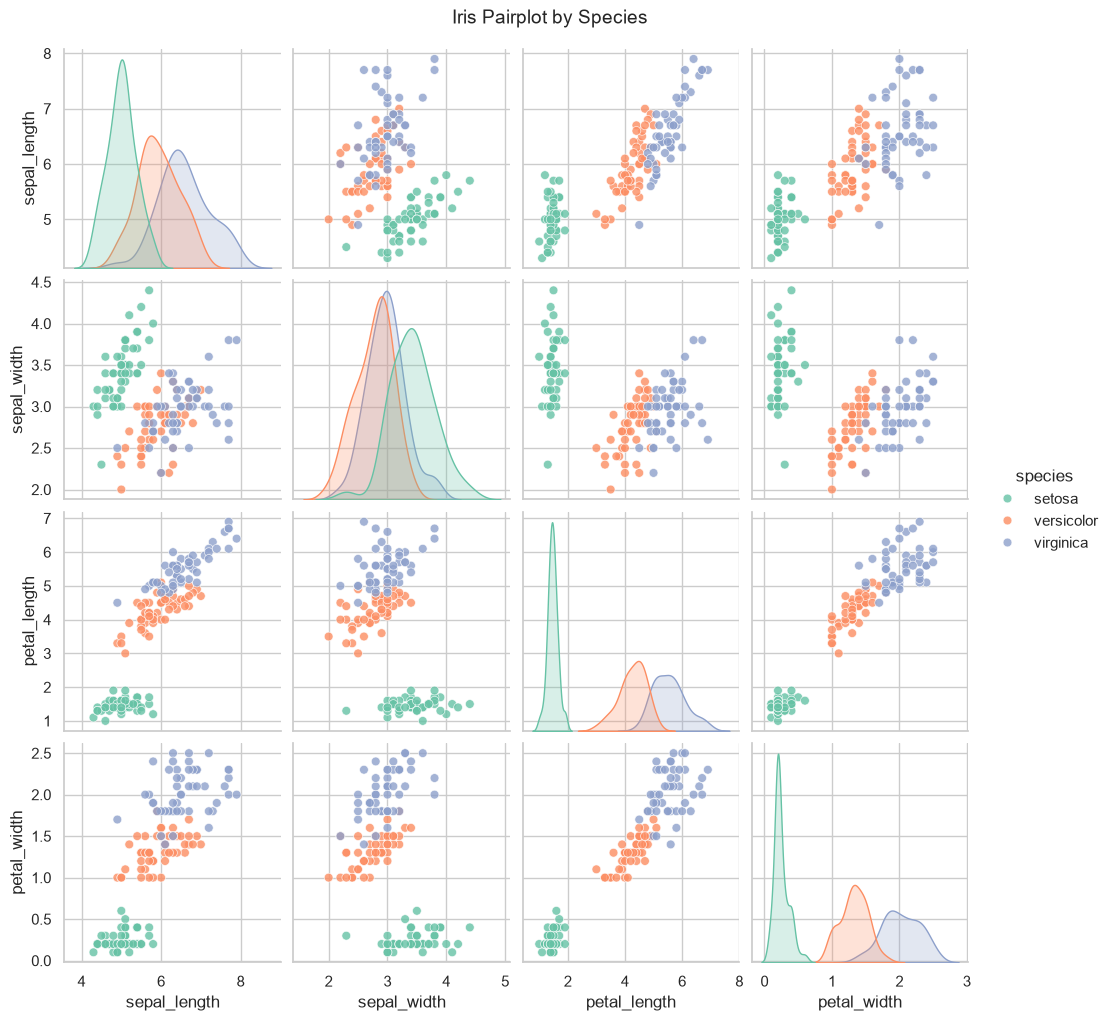

In [4]:
g = sns.pairplot(df, hue="species", diag_kind="kde", palette="Set2",
                 plot_kws={"alpha": 0.8, "s": 40})
g.figure.suptitle("Iris Pairplot by Species", y=1.02, fontsize=14)
plt.show()

**Observations:** *setosa* is linearly separable from the other two using the petal measurements. *versicolor* and *virginica* overlap slightly, which is where most misclassifications will occur. Petal length and width are the most discriminative features.

## 4. Train/test split (80/20) and feature scaling

In [5]:
X = df.drop(columns="species")
y = df["species"]
feature_names = X.columns.tolist()
class_names = sorted(y.unique())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)

# Fit the scaler on TRAIN only, then apply to test (avoids data leakage)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print(f"Train: {X_train.shape[0]} samples | Test: {X_test.shape[0]} samples")
print("Scaled train mean (~0):", X_train_s.mean(axis=0).round(3))
print("Scaled train std  (~1):", X_train_s.std(axis=0).round(3))

Train: 120 samples | Test: 30 samples
Scaled train mean (~0): [-0.  0.  0.  0.]
Scaled train std  (~1): [1. 1. 1. 1.]


## 5. Train the models

In [6]:
log_reg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
tree = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)

log_reg.fit(X_train_s, y_train)
tree.fit(X_train_s, y_train)

models = {"Logistic Regression": log_reg, "Decision Tree": tree}
preds = {name: m.predict(X_test_s) for name, m in models.items()}
print("Models trained.")

Models trained.


## 6. Evaluation

In [7]:
rows = []
for name, y_pred in preds.items():
    rows.append({
        "Model": name,
        "Accuracy":  accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(y_test, y_pred, average="macro"),
        "Recall (macro)":    recall_score(y_test, y_pred, average="macro"),
        "F1-score (macro)":  f1_score(y_test, y_pred, average="macro"),
    })
results = pd.DataFrame(rows).set_index("Model").round(4)
results

,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
Model,,,,
Logistic Regression,0.9333,0.9333,0.9333,0.9333
Decision Tree,0.9667,0.9697,0.9667,0.9666


In [8]:
for name, y_pred in preds.items():
    print("=" * 60)
    print(name)
    print("=" * 60)
    print(classification_report(y_test, y_pred, digits=3))

Logistic Regression
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.900     0.900     0.900        10
   virginica      0.900     0.900     0.900        10

    accuracy                          0.933        30
   macro avg      0.933     0.933     0.933        30
weighted avg      0.933     0.933     0.933        30

Decision Tree
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      1.000     0.900     0.947        10
   virginica      0.909     1.000     0.952        10

    accuracy                          0.967        30
   macro avg      0.970     0.967     0.967        30
weighted avg      0.970     0.967     0.967        30



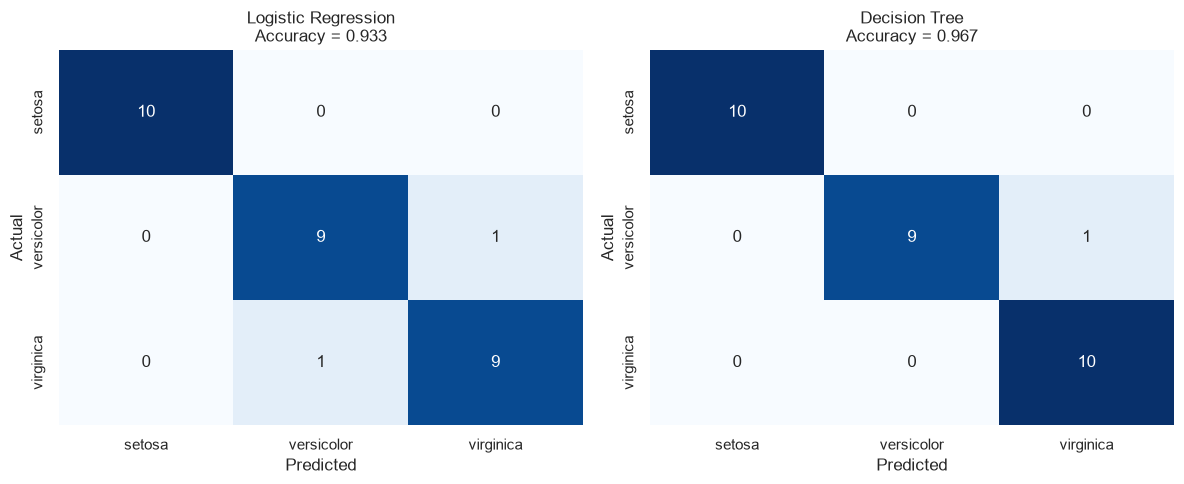

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, y_pred) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, y_pred, labels=class_names)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(f"{name}\nAccuracy = {accuracy_score(y_test, y_pred):.3f}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

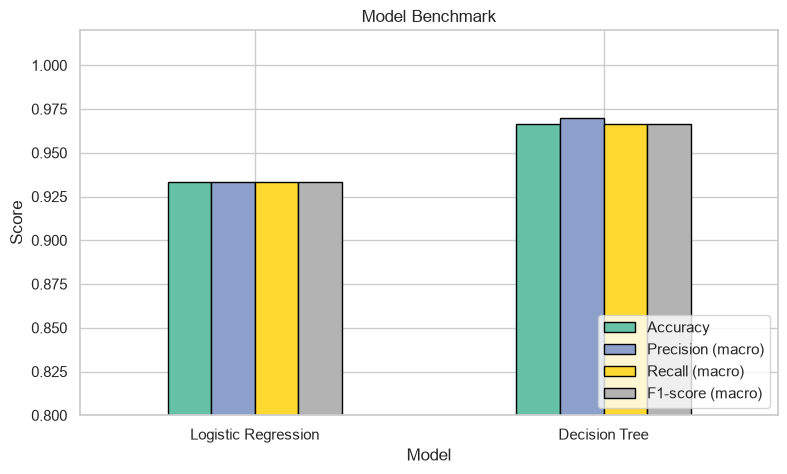

In [10]:
ax = results.plot(kind="bar", figsize=(9, 5), colormap="Set2", edgecolor="black")
ax.set_ylim(0.8, 1.02)
ax.set_title("Model Benchmark")
ax.set_ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

## 7. Decision boundary visualization

A decision boundary can only be drawn in 2-D, so here both models are retrained on the two most discriminative features (**petal length** and **petal width**), scaled with their own `StandardScaler`. This is for visualization only; the benchmark above uses all four features.

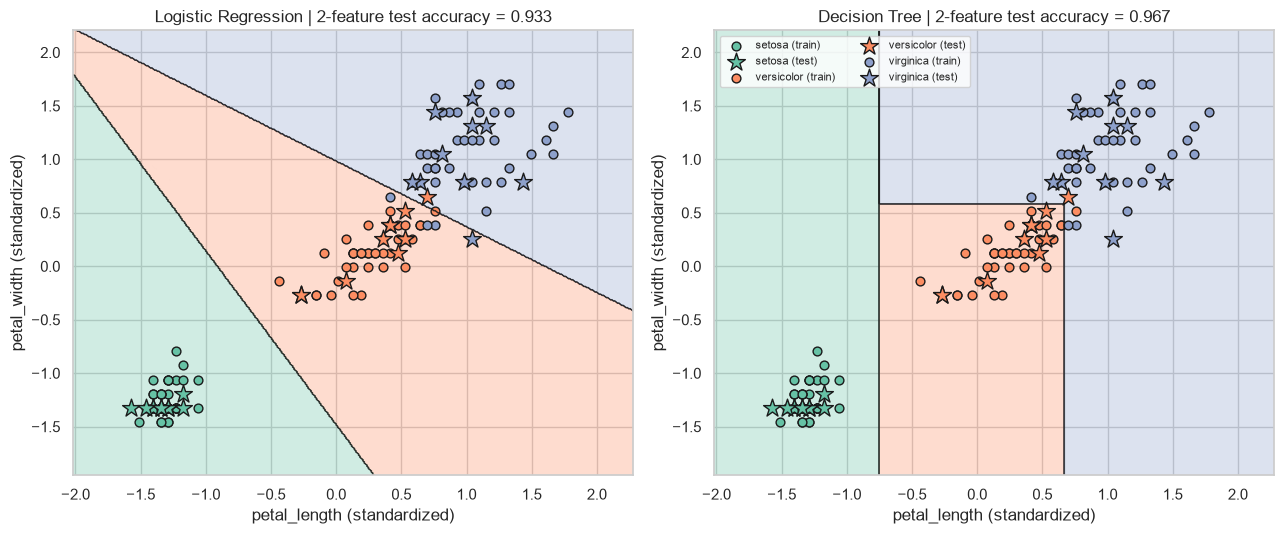

In [11]:
feat2 = ["petal_length", "petal_width"]
Xtr2, Xte2 = X_train[feat2], X_test[feat2]

sc2 = StandardScaler().fit(Xtr2)
Xtr2_s, Xte2_s = sc2.transform(Xtr2), sc2.transform(Xte2)

label_to_int = {c: i for i, c in enumerate(class_names)}
ytr_i = y_train.map(label_to_int).values
yte_i = y_test.map(label_to_int).values

models2d = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
}

# Mesh grid in scaled space
pad = 0.5
x_min, x_max = Xtr2_s[:, 0].min() - pad, Xtr2_s[:, 0].max() + pad
y_min, y_max = Xtr2_s[:, 1].min() - pad, Xtr2_s[:, 1].max() + pad
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 400), np.linspace(y_min, y_max, 400))
grid = np.c_[xx.ravel(), yy.ravel()]

colors = ["#66c2a5", "#fc8d62", "#8da0cb"]
from matplotlib.colors import ListedColormap
cmap = ListedColormap(colors)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (name, m) in zip(axes, models2d.items()):
    m.fit(Xtr2_s, ytr_i)
    Z = m.predict(grid).reshape(xx.shape)
    acc = accuracy_score(yte_i, m.predict(Xte2_s))
    ax.contourf(xx, yy, Z, alpha=0.3, cmap=cmap)
    ax.contour(xx, yy, Z, colors="k", linewidths=0.6, alpha=0.6)
    for i, c in enumerate(class_names):
        ax.scatter(Xtr2_s[ytr_i == i, 0], Xtr2_s[ytr_i == i, 1], c=colors[i],
                   edgecolor="k", s=40, label=f"{c} (train)")
        ax.scatter(Xte2_s[yte_i == i, 0], Xte2_s[yte_i == i, 1], c=colors[i],
                   edgecolor="k", marker="*", s=180, label=f"{c} (test)")
    ax.set_title(f"{name} | 2-feature test accuracy = {acc:.3f}")
    ax.set_xlabel("petal_length (standardized)")
    ax.set_ylabel("petal_width (standardized)")
axes[1].legend(loc="upper left", fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

## 8. Extras: decision tree structure and feature importance

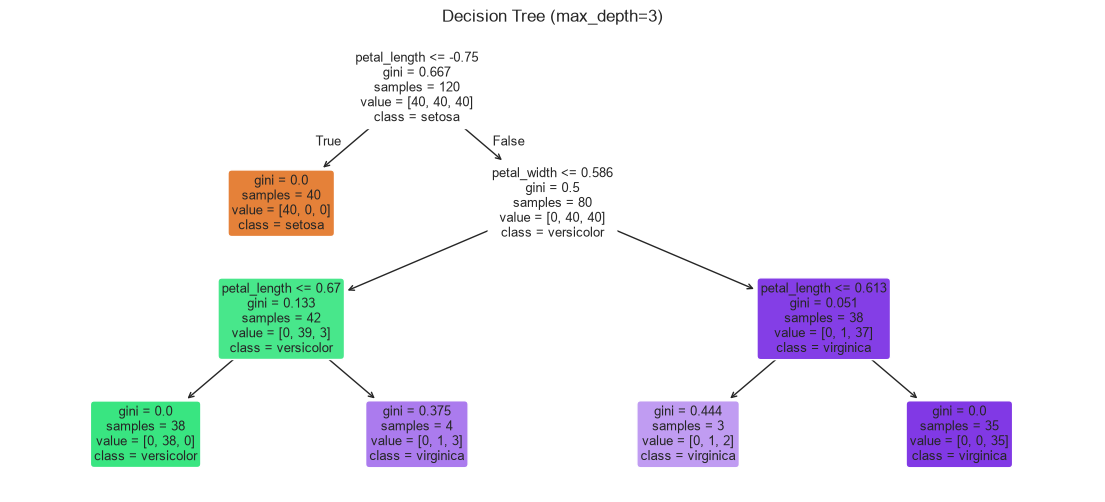

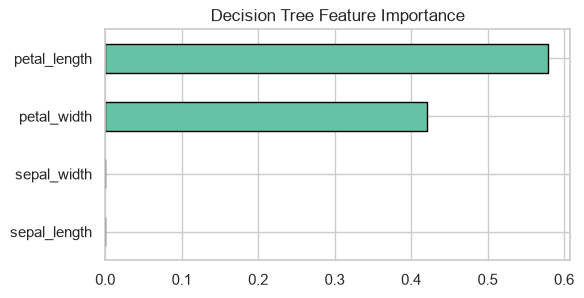

In [12]:
from sklearn.tree import plot_tree

fig, ax = plt.subplots(figsize=(14, 6))
plot_tree(tree, feature_names=feature_names, class_names=class_names,
          filled=True, rounded=True, fontsize=9, ax=ax)
plt.title("Decision Tree (max_depth=3)")
plt.show()

imp = pd.Series(tree.feature_importances_, index=feature_names).sort_values()
imp.plot(kind="barh", figsize=(6, 3), color="#66c2a5", edgecolor="black",
         title="Decision Tree Feature Importance")
plt.show()

## 9. Conclusion

- Both models reach high accuracy on Iris; *setosa* is classified perfectly, and any errors occur between *versicolor* and *virginica*.
- **Logistic Regression** gives smooth, linear decision boundaries and benefits directly from `StandardScaler`.
- **Decision Tree** gives axis-aligned, rectangular boundaries and is easy to interpret, but is more prone to overfitting (hence `max_depth=3`). Trees are not sensitive to scaling, but scaling was applied for consistency as required.
- With only 30 test samples, one misclassification moves accuracy by about 3.3 points, so for a more robust comparison use cross-validation (e.g. `cross_val_score` with 5 folds).